**MAESTRÍA EN INTELIGENCIA ARTIFICIAL APLICADA**

**Curso: TC5053 - Ciencia y analítica de datos**

Tecnológico de Monterrey

Prof Grettel Barceló Alonso

**Semana 5**
Preprocesamiento de datos

---

*   NOMBRE: Gael Isaac Jurado Romero
*   MATRÍCULA: A01841366

En esta actividad trabajarás con el archivo `heart_disease.csv`, basado en un conjunto de datos sobre pacientes y variables clínicas relacionadas con enfermedades cardíacas, disponible en Kaggle.

Los datos fueron recopilados para analizar la presencia de enfermedades cardíacas en los pacientes y contienen información demográfica, clínica y resultados de pruebas diagnósticas. Los indicadores incluidos son:

* `id`: Identificador único de cada paciente
* `age`: Edad del paciente en años
* `origin`: Lugar de estudio
* `sex`: Masculino / Femenino
* `cp`: Tipo de dolor torácico (angina típica, angina atípica, no anginal, asintomático)
* `trestbps`: Presión arterial en reposo (en mm Hg al ingreso al hospital)
* `chol`: Colesterol sérico en mg/dl
* `fbs`: Si el azúcar en ayunas > 120 mg/dl
* `restecg`: Resultados del electrocardiograma en reposo (normal, anomalía ST-T, hipertrofia ventricular izquierda)
* `thalach`: Frecuencia cardíaca máxima alcanzada
* `exang`: Angina inducida por ejercicio (Verdadero / Falso)
* `oldpeak`: Depresión del segmento ST inducida por ejercicio respecto al reposo
* `slope`: Pendiente del segmento ST en el pico de ejercicio
* `ca`: Número de vasos principales coloreados por fluoroscopía (0 - 3)
* `thal`: Resultado de la prueba de perfusión cardíaca (normal, defecto fijo, defecto reversible)
* `num`: Indica si el paciente tiene o no enfermedad cardíaca, o el grado de enfermedad (0 = sano, 1 - 4 = enfermedad) Es la variable de salida o *target*, es decir, la que se pretende predecir más adelante al construir el modelo.

**NOTA IMPORTANTE:** Asegúrate de responder *explícitamente* todos los cuestionamientos.

In [1]:
# Importar las bibliotecas necesarias
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from sklearn.impute import SimpleImputer

1. Descarga el archivo: `heart_disease.csv` y guarda, en un dataframe (`cardio_df`), todos sus registros.
* Haz que la columna `id` sea el índice del dataframe.
* Utiliza el método `info()` del dataframe, para obtener el resumen de los tipos de datos. ¿Cuántas columnas son numéricas y cuántas de texto?
* Determina la cantidad de valores únicos por columna.

In [2]:
url = "https://raw.githubusercontent.com/GJ030/Ciencia_datos/main/5.2%20Actividad%205%20-%20Preprocesamiento/heart_disease.csv"
cardio_df = pd.read_csv(url, index_col="id")
cardio_df.info()
cardio_df.nunique()

<class 'pandas.core.frame.DataFrame'>
Index: 918 entries, 1 to 920
Data columns (total 15 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       918 non-null    int64  
 1   sex       918 non-null    object 
 2   origin    918 non-null    object 
 3   cp        918 non-null    object 
 4   trestbps  859 non-null    float64
 5   chol      888 non-null    float64
 6   fbs       829 non-null    object 
 7   restecg   918 non-null    object 
 8   thalch    863 non-null    float64
 9   exang     863 non-null    object 
 10  oldpeak   856 non-null    float64
 11  slope     610 non-null    object 
 12  ca        309 non-null    float64
 13  thal      434 non-null    object 
 14  num       918 non-null    int64  
dtypes: float64(5), int64(2), object(8)
memory usage: 114.8+ KB


age          50
sex           2
origin        4
cp            4
trestbps     60
chol        216
fbs           2
restecg       3
thalch      119
exang         2
oldpeak      53
slope         3
ca            4
thal          3
num           5
dtype: int64

**Respuesta 1.** Según `info()` hay **7 columnas numéricas** (2 `int64` y 5 `float64`) y **8 columnas de texto** (`object`). Entre las numéricas, `ca` (4 valores únicos) y `num` (5) tienen muy pocos valores únicos.

2. Examina las variables numéricas que presentan pocos valores únicos, ya que esto puede indicar que en realidad se tratan de variables categóricas codificadas como números.
* Si existen casos de este tipo, conviértelas a categóricas. Antes de hacerlo, revisa sus descripciones para determinar si son ordinales o nominales y, si son ordinales, establece el orden correcto de las categorías.

In [3]:
cardio_df["ca"] = cardio_df["ca"].astype(pd.CategoricalDtype([0, 1, 2, 3], ordered=True))
cardio_df["num"] = cardio_df["num"].astype(pd.CategoricalDtype([0, 1, 2, 3, 4], ordered=True))
cardio_df[["ca", "num"]].dtypes

ca     category
num    category
dtype: object

**Respuesta 2.** Las únicas numéricas con pocos valores únicos son `ca` (4) y `num` (5); las demás (`age`, `trestbps`, `chol`, `thalch`, `oldpeak`) tienen 50 o más. Ambas son **ordinales**: `ca` cuenta los vasos coloreados (0 < 1 < 2 < 3) y `num` es el grado de enfermedad (0 = sano < 1 < 2 < 3 < 4), así que se convirtieron en categóricas ordenadas con ese orden. Ninguna es nominal.

3. Obtén las estadísticas descriptivas de las variables, realizando el análisis por separado para las variables numéricas y las categóricas.
* Para las numéricas, incluye el sesgo y la curtosis.
* Para las categóricas, imprime además las tablas de frecuencia.

In [4]:
num_cols = cardio_df.select_dtypes(include="number").columns
stats = cardio_df[num_cols].describe().T
stats["skew"] = cardio_df[num_cols].skew()
stats["kurtosis"] = cardio_df[num_cols].kurt()
stats

,count,mean,std,min,25%,50%,75%,max,skew,kurtosis
age,918.0,53.530501,9.412783,28.0,47.0,54.0,60.0,77.0,-0.193710,-0.382511
trestbps,859.0,132.294529,18.535875,80.0,120.0,130.0,140.0,200.0,0.630411,0.632992
chol,888.0,242.189189,53.424806,85.0,216.0,223.0,268.0,603.0,1.640672,6.573848
thalch,863.0,137.528389,25.950226,60.0,120.0,140.0,157.0,202.0,-0.209319,-0.483939
oldpeak,856.0,0.880607,1.091840,-2.6,0.0,0.5,1.5,6.2,1.037990,1.119834


In [5]:
cat_cols = cardio_df.select_dtypes(exclude="number").columns
cardio_df[cat_cols].describe()

,sex,origin,cp,fbs,restecg,exang,slope,ca,thal,num
count,918,918,918,829,918,863,610,309,434,918
unique,2,4,4,2,3,2,3,4,3,5
top,Male,Cleveland,asymptomatic,False,normal,False,flat,0,normal,0
freq,724,304,495,691,551,526,345,181,196,411


In [6]:
for col in cat_cols:
    print(cardio_df[col].value_counts(), "\n")

sex
Male      724
Female    194
Name: count, dtype: int64 

origin
Cleveland        304
Hungary          292
VA Long Beach    200
Switzerland      122
Name: count, dtype: int64 

cp
asymptomatic       495
non-anginal        204
atypical angina    174
typical angina      45
Name: count, dtype: int64 

fbs
False    691
True     138
Name: count, dtype: int64 

restecg
normal              551
lv hypertrophy      188
st-t abnormality    179
Name: count, dtype: int64 

exang
False    526
True     337
Name: count, dtype: int64 

slope
flat           345
upsloping      202
downsloping     63
Name: count, dtype: int64 

ca
0    181
1     67
2     41
3     20
Name: count, dtype: int64 

thal
normal               196
reversable defect    192
fixed defect          46
Name: count, dtype: int64 

num
0    411
1    263
2    109
3    107
4     28
Name: count, dtype: int64 



**Respuesta 3.** Numéricas: `chol` es la más asimétrica (sesgo 1.64) y de colas pesadas (curtosis 6.57), seguida de `oldpeak` (sesgo 1.04, curtosis 1.12) y `trestbps` (0.63 y 0.63); `age` y `thalch` son casi simétricas (sesgos de -0.19 y -0.21). Categóricas: la mayoría de los pacientes son hombres (724 de 918), el tipo de dolor más frecuente es el asintomático (495) y 411 pacientes no tienen enfermedad (`num` = 0). `slope`, `ca` y `thal` tienen menos registros que el resto (610, 309 y 434).

4. Calcula el porcentaje de valores faltantes en cada columna.
* Elimina aquellas columnas cuyo porcentaje de valores faltantes supere el 30%.
* Crea un mapa de calor que visualice la distribución de los valores faltantes en todas las columnas restantes.
* Algunas variables presentan valores faltantes de manera simultánea; es decir, en el mapa se pueden identificar filas donde varias están ausentes al mismo tiempo. Enumera cuáles son dichas variables e investiga si esta concurrencia tiene sentido desde un punto de vista médico o clínico.

In [7]:
missing_pct = cardio_df.isna().mean() * 100
missing_pct.round(2)

age          0.00
sex          0.00
origin       0.00
cp           0.00
trestbps     6.43
chol         3.27
fbs          9.69
restecg      0.00
thalch       5.99
exang        5.99
oldpeak      6.75
slope       33.55
ca          66.34
thal        52.72
num          0.00
dtype: float64

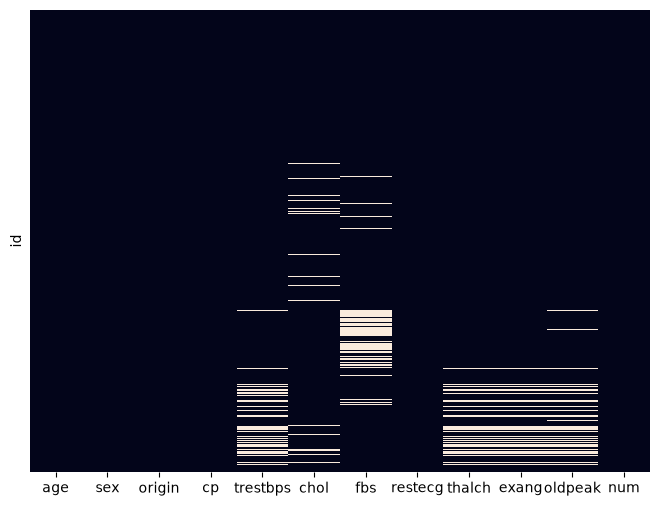

In [8]:
cardio_df = cardio_df.drop(columns=missing_pct[missing_pct > 30].index)

plt.figure(figsize=(8, 6))
sns.heatmap(cardio_df.isna(), yticklabels=False, cbar=False)
plt.show()

**Respuesta 4.** Superan el 30% de faltantes `slope` (33.55%), `ca` (66.34%) y `thal` (52.72%), por lo que se eliminaron; las demás tienen menos de 10%. En el mapa de calor (las franjas claras son valores faltantes) `thalch`, `exang` y `oldpeak` faltan **simultáneamente** en las mismas filas, mientras que `trestbps`, `chol` y `fbs` tienen faltantes en su mayoría en filas distintas. Esta concurrencia tiene sentido clínico: las tres variables provienen de la misma prueba de esfuerzo (frecuencia cardíaca máxima alcanzada, angina inducida por ejercicio y depresión del segmento ST inducida por ejercicio), de modo que si la prueba no se realizó o no se completó (contraindicación, incapacidad física del paciente o falta del estudio en el centro) los tres resultados se pierden a la vez.

5. Si centramos el análisis en una de las variables identificadas en el ejercicio anterior, se puede suponer que los hallazgos obtenidos podrían ser aplicables a las demás variables que presentan un patrón similar.

* ¿Tendrán los valores faltantes de `thalch` relación con alguna otra variable? Analízalo considerando las siguientes columnas:
  *   Numéricas: `age`, `chol`
  *   Categóricas: `restecg`, `cp`

Para ello deberás dividir cada columna en dos grupos: con / sin faltantes en `thalch` y utilizar métodos gráficos y pruebas de hipótesis para ver si hay diferencias significativas.
* Incluye las conclusiones del análisis con los resultados obtenidos.
* Justifica si el mecanismo de faltantes de `thalch` es MCAR (*Missing Completely at Random*) o MAR (*Missing at Random*).

**NOTA**. Puedes reutilizar las funciones `Diagnose_MV_Numerical` y `Diagnose_MV_Categorical` definidas en Hands-On-Prep_Missing_Values.zip. Revisa nuevamente cómo utilizarlas.

In [9]:
from scipy.stats import ttest_ind
def Diagnose_MV_Numerical(df,str_att_name,BM_MV):
    MV_labels = {True:'With Missing Values',False:'Without Missing Values'}

    labels=[]
    box_sr = pd.Series('',index = BM_MV.unique())
    for poss in BM_MV.unique():
        BM = BM_MV == poss
        box_sr[poss] = df[BM][str_att_name].dropna()
        labels.append(MV_labels[poss])

    plt.boxplot(box_sr,orientation="horizontal")
    plt.yticks([1,2],labels)
    plt.xlabel(str_att_name)
    plt.show()

    plt.figure(figsize=(10,4))

    att_range = (df[str_att_name].min(),df[str_att_name].max())

    for i,poss in enumerate(BM_MV.unique()):
        plt.subplot(1,2,i+1)
        BM = BM_MV == poss
        df[BM][str_att_name].hist()
        plt.xlim = att_range
        plt.xlabel(str_att_name)
        plt.title(MV_labels[poss])

    plt.show()

    group_1_data = df[BM_MV][str_att_name].dropna()
    group_2_data = df[~BM_MV][str_att_name].dropna()

    p_value = ttest_ind(group_1_data,group_2_data).pvalue

    print('p-value of t-test: {}'.format(p_value))

In [10]:
from scipy.stats import chi2_contingency
def Diagnose_MV_Categorical(df,str_att_name,BM_MV):
    MV_labels = {True:'With Missing Values',False:'Without Missing Values'}

    plt.figure(figsize=(10,4))
    for i,poss in enumerate(BM_MV.unique()):
        plt.subplot(1,2,i+1)
        BM = BM_MV == poss
        df[BM][str_att_name].value_counts().plot.bar()
        plt.title(MV_labels[poss])
    plt.show()

    contigency_table = pd.crosstab(BM_MV,df[str_att_name])
    p_value = chi2_contingency(contigency_table)[1]

    print('p-value of Chi_squared test: {}'.format(p_value))

Diagnóstico de los faltantes de thalch según age:


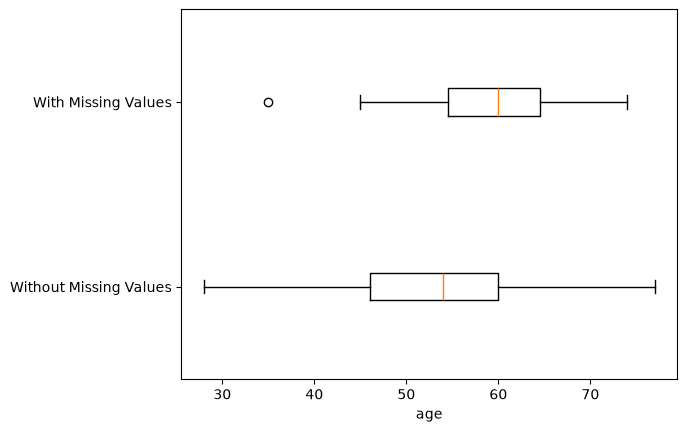

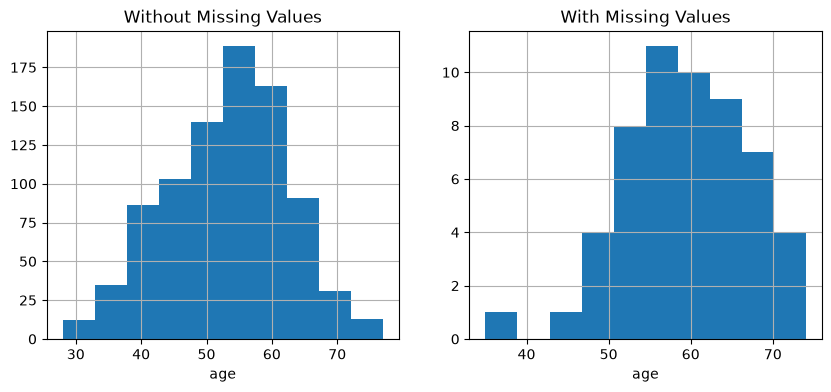

p-value of t-test: 1.5041244185890923e-06
- - - - - - - - - - - - divider - - - - - - - - - - - 
Diagnóstico de los faltantes de thalch según chol:


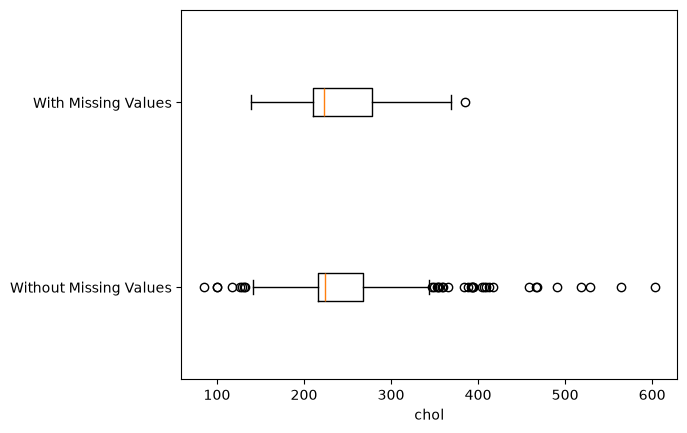

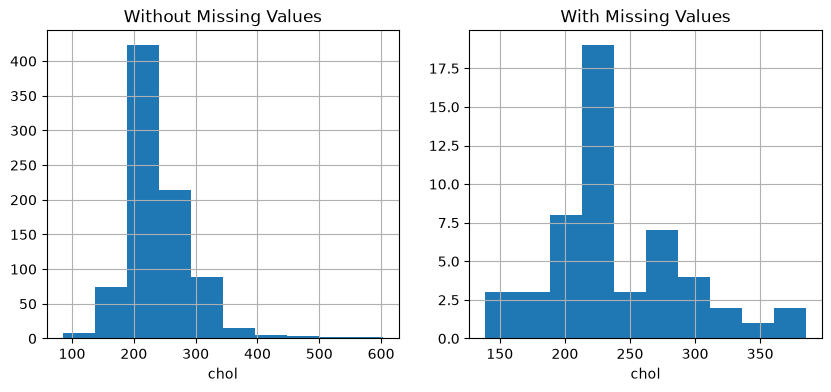

p-value of t-test: 0.7165289974295669
- - - - - - - - - - - - divider - - - - - - - - - - - 


In [11]:
BM_MV = cardio_df["thalch"].isna()

for att in ["age", "chol"]:
    print(f"Diagnóstico de los faltantes de thalch según {att}:")
    Diagnose_MV_Numerical(cardio_df, att, BM_MV)
    print("- - - - - - - - - - - - divider - - - - - - - - - - - ")

Diagnóstico de los faltantes de thalch según restecg:


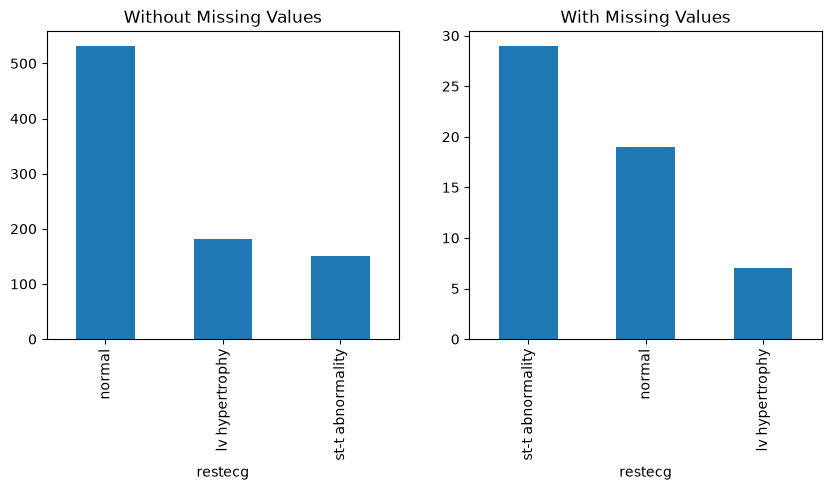

p-value of Chi_squared test: 1.1472889573985467e-09
- - - - - - - - - - - - divider - - - - - - - - - - - 
Diagnóstico de los faltantes de thalch según cp:


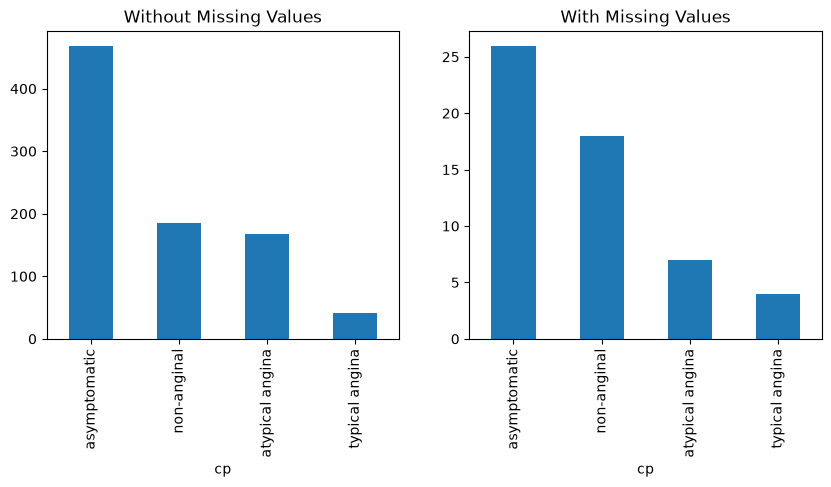

p-value of Chi_squared test: 0.15420097177251701
- - - - - - - - - - - - divider - - - - - - - - - - - 


In [12]:
for att in ["restecg", "cp"]:
    print(f"Diagnóstico de los faltantes de thalch según {att}:")
    Diagnose_MV_Categorical(cardio_df, att, BM_MV)
    print("- - - - - - - - - - - - divider - - - - - - - - - - - ")

**Respuesta 5.** Resultados de comparar los pacientes con y sin faltantes en `thalch` (α = 0.05):

| Variable | Prueba | p-value | ¿Diferencia significativa? |
|---|---|---|---|
| `age` | t de Student | 1.5e-06 | Sí |
| `chol` | t de Student | 0.72 | No |
| `restecg` | Chi cuadrada | 1.1e-09 | Sí |
| `cp` | Chi cuadrada | 0.15 | No |

Los pacientes con `thalch` faltante tienden a ser mayores (su boxplot e histograma están desplazados hacia edades más altas) y entre ellos predomina la anomalía ST-T en `restecg`, mientras que entre los pacientes sin faltantes predomina el ECG normal. En `chol` y `cp` las distribuciones de ambos grupos son similares.

El mecanismo es **MAR**: no es MCAR porque la ausencia de `thalch` no es independiente de las demás variables (depende de `age` y `restecg`, que sí están observadas), y basta una relación significativa para descartarlo. La falta de relación con `chol` y `cp` no cambia esta conclusión. Que dependa de variables observadas es justo la definición de MAR; con estos datos no se puede comprobar que no dependa además del propio valor no observado (MNAR). Como `exang` y `oldpeak` faltan en las mismas filas, la conclusión se extiende a ellas.

6. La imputación de una variable con valores faltantes puede realizarse por grupos o segmentos relevantes. Esto significa que, en lugar de utilizar una estadística global de toda la columna, se calcula la estadística correspondiente dentro de cada grupo definido por otra variable, haciendo:

> `df['var_with_missing'] = df.groupby('related_var')['var_with_missing'].transform(lambda x: x.fillna(x.median()))`

* Utiliza la variable `restecg` para separar los grupos e imputar `thalch` y todas las variables con patrón de faltantes similar (identificadas en el ejercicio 4) Asegúrate de cambiar la función de agregado si hay variables no numéricas.
* Vuelve a generar el mapa de calor para verificar que los valores faltantes en estas variables hayan sido imputados.

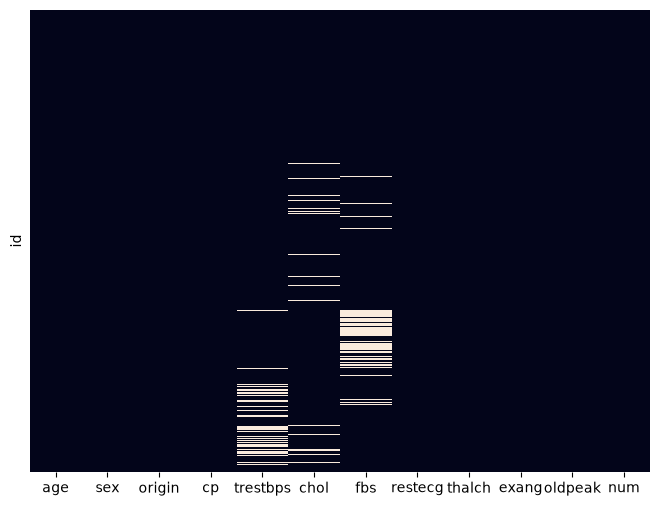

In [13]:
for col in ["thalch", "oldpeak"]:
    cardio_df[col] = cardio_df.groupby("restecg")[col].transform(lambda x: x.fillna(x.median()))

# where en lugar de fillna: fillna sobre object con True/False emite FutureWarning
cardio_df["exang"] = cardio_df.groupby("restecg")["exang"].transform(lambda x: x.where(x.notna(), x.mode()[0]))

plt.figure(figsize=(8, 6))
sns.heatmap(cardio_df.isna(), yticklabels=False, cbar=False)
plt.show()

**Respuesta 6.** Se imputaron `thalch` y `oldpeak` (numéricas) con la **mediana** de cada grupo de `restecg` y `exang` (categórica) con su **moda**, porque la mediana no se ve afectada por los valores extremos de `oldpeak` (sesgo 1.04) y la moda es la única estadística válida para una variable categórica. Se agrupó por `restecg` porque no tiene faltantes y la pregunta 5 mostró que los faltantes de `thalch` dependen de ella. El nuevo mapa de calor confirma que `thalch`, `exang` y `oldpeak` ya no tienen faltantes; quedan `trestbps`, `chol` y `fbs`.

7. Para las variables que aún presentan valores faltantes, realiza la imputación utilizando estadísticas generales calculadas sobre toda la columna, sin segmentar por grupos. Esta vez utiliza la clase `SimpleImputer` de sklearn
* Justifica la estrategia (*mean, median, most_frequent*) que emplees en cada caso.


In [14]:
cardio_df[["trestbps", "chol"]] = SimpleImputer(strategy="median").fit_transform(cardio_df[["trestbps", "chol"]])
cardio_df[["fbs"]] = SimpleImputer(strategy="most_frequent").fit_transform(cardio_df[["fbs"]])
cardio_df.isna().sum()

age         0
sex         0
origin      0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalch      0
exang       0
oldpeak     0
num         0
dtype: int64

**Respuesta 7.** `trestbps` y `chol` se imputaron con la **mediana** (`median`), porque son asimétricas y con valores extremos (sesgos de 0.63 y 1.64, y curtosis de 6.57 en `chol`), de modo que la media se desplazaría hacia los extremos. `fbs` se imputó con la **moda** (`most_frequent`), porque es categórica y no admite media ni mediana. El resultado muestra 0 valores faltantes en todas las columnas.

8. Dibuja boxplots de todas las variables numéricas.
* Obtén los valores atípicos mediante el método gráfico, a partir del objeto devuelto por el boxplot.

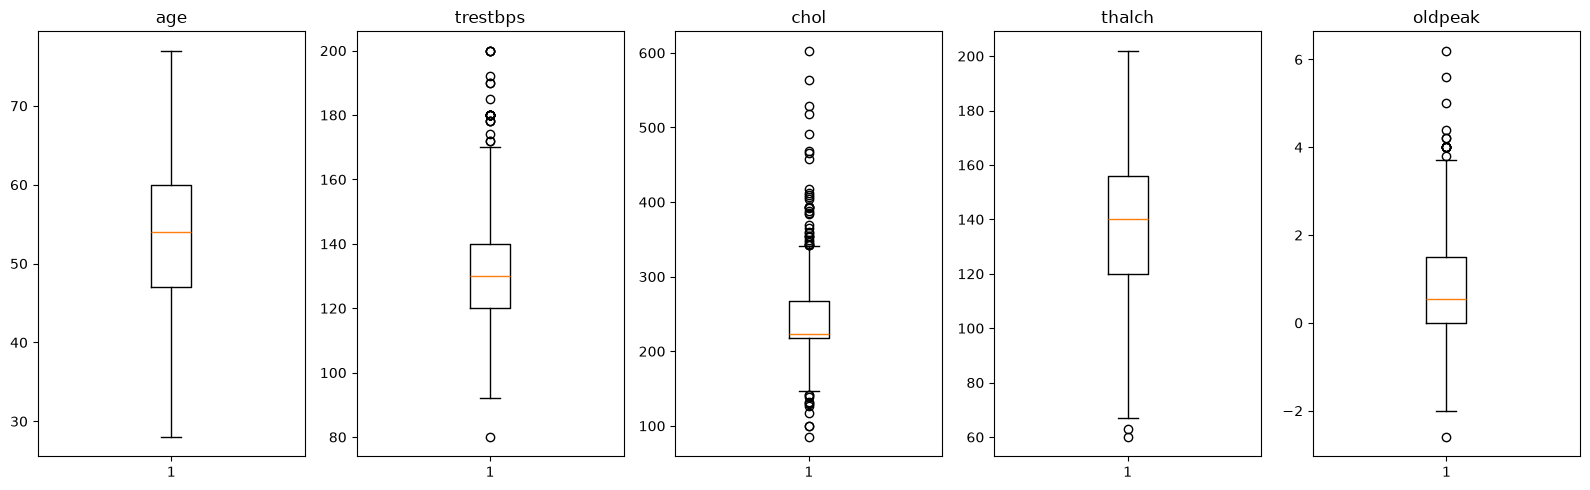

age: 0 valores atípicos -> []
trestbps: 27 valores atípicos -> [ 80. 172. 172. 174. 178. 178. 178. 180. 180. 180. 180. 180. 180. 180.
 180. 180. 180. 180. 180. 185. 190. 190. 192. 200. 200. 200. 200.]
chol: 44 valores atípicos -> [ 85. 100. 100. 117. 126. 129. 131. 132. 139. 141. 142. 342. 342. 342.
 344. 347. 349. 353. 354. 355. 358. 360. 365. 369. 384. 385. 388. 392.
 393. 394. 394. 404. 407. 409. 412. 417. 458. 466. 468. 491. 518. 529.
 564. 603.]
thalch: 2 valores atípicos -> [60. 63.]
oldpeak: 16 valores atípicos -> [-2.6  3.8  4.   4.   4.   4.   4.   4.   4.   4.   4.2  4.2  4.4  5.
  5.6  6.2]


In [15]:
num_cols = cardio_df.select_dtypes(include="number").columns

fig, axes = plt.subplots(1, len(num_cols), figsize=(16, 5))
outliers = {}
for ax, col in zip(axes, num_cols):
    bp = ax.boxplot(cardio_df[col])
    outliers[col] = np.sort(bp["fliers"][0].get_ydata())
    ax.set_title(col)
plt.tight_layout()
plt.show()

for col, vals in outliers.items():
    print(f"{col}: {len(vals)} valores atípicos -> {vals}")

**Respuesta 8.** Con los elementos `fliers` de cada boxplot se obtuvieron los valores atípicos: `age` 0, `trestbps` 27 (un valor bajo, 80, y el resto entre 172 y 200), `chol` 44 (en ambos extremos, de 85 a 142 y de 342 a 603), `thalch` 2 (60 y 63) y `oldpeak` 16 (uno negativo, -2.6, y el resto entre 3.8 y 6.2).

9. Para la variable `trestbps`, calcula los valores atípicos utilizando el método del rango intercuartílico (IQR).
* Para ello obtén los cuartiles necesarios y determina los límites superior e inferior para filtrar los valores que se encuentren fuera de ese rango.
* Verifica si los resultados coinciden con los obtenidos en el ejercicio anterior.

In [16]:
q1, q3 = cardio_df["trestbps"].quantile([0.25, 0.75])
iqr = q3 - q1
lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
trestbps_out = cardio_df["trestbps"][(cardio_df["trestbps"] < lower) | (cardio_df["trestbps"] > upper)]

print(f"Q1 = {q1}, Q3 = {q3}, IQR = {iqr}, límites = [{lower}, {upper}]")
print(f"{len(trestbps_out)} valores atípicos -> {np.sort(trestbps_out.values)}")
print("Coinciden con el boxplot:", np.array_equal(np.sort(trestbps_out.values), outliers["trestbps"]))

Q1 = 120.0, Q3 = 140.0, IQR = 20.0, límites = [90.0, 170.0]
27 valores atípicos -> [ 80. 172. 172. 174. 178. 178. 178. 180. 180. 180. 180. 180. 180. 180.
 180. 180. 180. 180. 180. 185. 190. 190. 192. 200. 200. 200. 200.]
Coinciden con el boxplot: True


**Respuesta 9.** Con Q1 = 120, Q3 = 140 y IQR = 20, los límites son 90 (inferior) y 170 (superior), y quedan fuera 27 valores. **Sí coinciden** con los obtenidos con el boxplot (la comparación da `True`): es esperable, porque el boxplot usa la misma regla de 1.5 × IQR para dibujar los bigotes.

10. Elimina los valores atípicos identificados de la variable `trestbps`.
* Dibuja el boxplot final para visualizar la distribución depurada.

(891, 12)


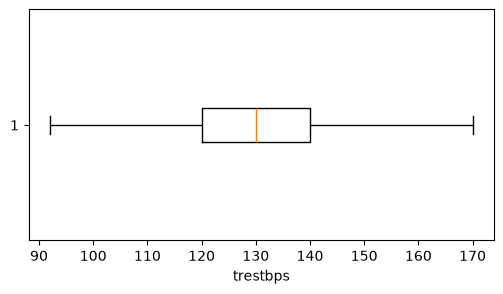

In [17]:
cardio_df = cardio_df.drop(trestbps_out.index)
print(cardio_df.shape)

plt.figure(figsize=(6, 3))
plt.boxplot(cardio_df["trestbps"], orientation="horizontal")
plt.xlabel("trestbps")
plt.show()

**Respuesta 10.** Se eliminaron los 27 valores atípicos de `trestbps`, con lo que el dataframe pasó de 918 a 891 registros. El boxplot final ya no muestra puntos fuera de los bigotes.

---

**Declaración de uso de IA**

*   Anthropic. (2026). *Claude Code (basado en Claude Sonnet 5.5)* [Modelo de lenguaje grande], utilizado para generación de código, depuración y redacción de los análisis. https://claude.com/claude-code

---